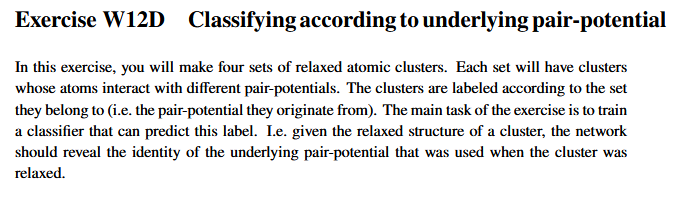

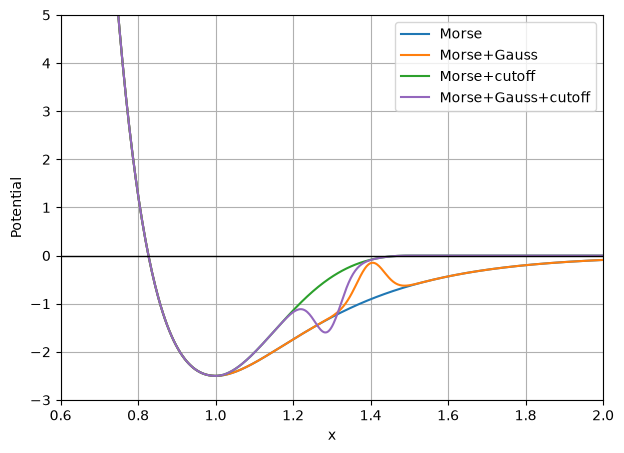

In [6]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

class Calc(torch.nn.Module):
    def __init__(self, r0=1.0, a=4.0, eps=2.5, rcut=1.0, lamb=0.5, gauss_r0=np.sqrt(2.0), gauss_sig=0.05, gauss_eps=-10.0):
        super().__init__()
        self.r0 = torch.nn.Parameter(torch.tensor(r0))
        self.a = torch.nn.Parameter(torch.tensor(a))
        self.eps = torch.nn.Parameter(torch.tensor(eps))
        self.gauss_r0 = torch.nn.Parameter(torch.tensor(gauss_r0))
        self.gauss_sig = torch.nn.Parameter(torch.tensor(gauss_sig))
        self.gauss_eps = torch.nn.Parameter(torch.tensor(gauss_eps))
        self.rcut = torch.nn.Parameter(torch.tensor(rcut))
        self.lamb = torch.nn.Parameter(torch.tensor(lamb))

    def cosine_cutoff(self, r):
        f = torch.zeros_like(r)
        mask1 = r <= self.rcut
        mask2 = (r > self.rcut) & (r < self.rcut + self.lamb)
        f[mask1] = 1.0
        f[mask2] = 0.5 + 0.5 * torch.cos(torch.pi * (r[mask2] - self.rcut) / self.lamb)
        return f

    def V(self, r):
        f = self.cosine_cutoff(r)
        g = self.gauss_eps * torch.exp(-((r - self.gauss_r0)**2) / self.gauss_sig**2)
        morse = self.eps * ((1.0 - torch.exp(-self.a * (r - self.r0)))**2 - 1.0)
        return f * (g + morse)

    def forward(self, r):
        return self.V(r)

calc1 = Calc(r0=1.0, a=4.0, eps=2.5, rcut=10.0, lamb=0.1, gauss_r0=10.0, gauss_eps=0.0)
calc2 = Calc(r0=1.0, a=4.0, eps=2.5, rcut=10.0, lamb=0.1, gauss_r0=1.4, gauss_eps=0.75)
calc3 = Calc(r0=1.0, a=4.0, eps=2.5, rcut=1.0, lamb=0.5, gauss_r0=10.0, gauss_eps=0.0)
calc4 = Calc(r0=1.0, a=4.0, eps=2.5, rcut=1.0, lamb=0.5, gauss_r0=1.3, gauss_eps=-3.0)

for calc in [calc1, calc2, calc3, calc4]:
    for p in calc.parameters():
        p.requires_grad = False

r_vals = torch.linspace(0.6, 2.0, 500)
labels = ['Morse', 'Morse+Gauss', 'Morse+cutoff', 'Morse+Gauss+cutoff']
colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:purple']

plt.figure(figsize=(7, 5))
for idx, calc in enumerate([calc1, calc2, calc3, calc4]):
    v_vals = calc(r_vals)
    plt.plot(r_vals.numpy(), v_vals.numpy(), label=labels[idx], color=colors[idx])
    
plt.axhline(0, color='black', linewidth=1)
plt.xlim(0.6, 2.0)
plt.ylim(-3, 5)
plt.xlabel('x')
plt.ylabel('Potential')
plt.grid(True)
plt.legend()
plt.show()

The code above defines a "calculator" class for pair-potentials in PyTorch, utilizing autograd to differentiate the energy expressions. We instantiate four different potentials (Morse, Morse with Gauss perturbation, Morse with a cutoff, and a combination of Morse, Gauss, and cutoff) by specifying precise hyperparameters. Then, `requires_grad = False` is set for the internal parameters within these calculators because they must remain fixed to generate the corresponding four plots illustrating the underlying energy profiles of the atomic interactions.


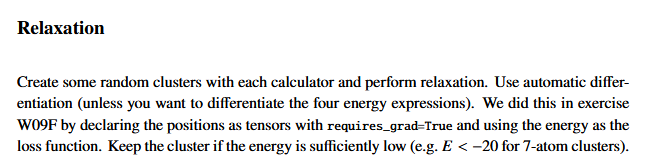
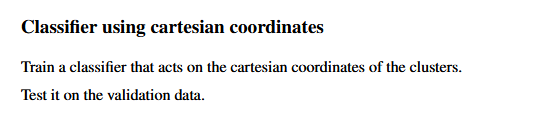

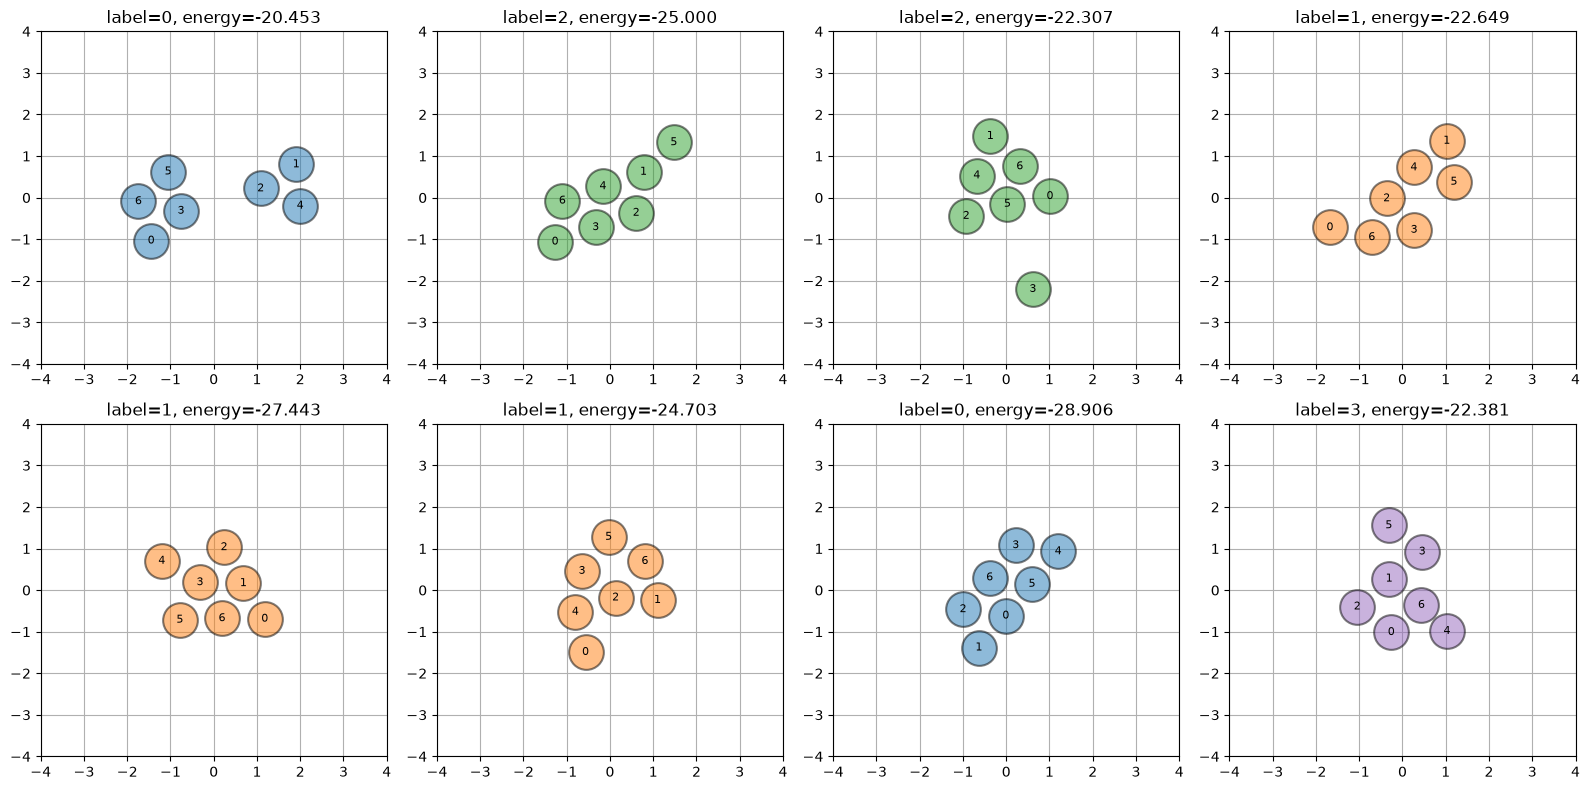

In [7]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

calc1.to(device)
calc2.to(device)
calc3.to(device)
calc4.to(device)

def relax_clusters_batched(calc, n_clusters, n_atoms=7, max_steps=500, lr=0.01):
    pos = torch.randn(n_clusters, n_atoms, 2, device=device, requires_grad=True)
    optimizer = optim.Adam([pos], lr=lr)
    
    eye_n = torch.eye(n_atoms, device=device)
    mask = 1 - eye_n
    
    for _ in range(max_steps):
        optimizer.zero_grad()
        diff = pos.unsqueeze(2) - pos.unsqueeze(1)
        dist = torch.norm(diff, dim=-1)
        dist = dist + eye_n * 1e-6
        
        energies = 0.5 * torch.sum(calc(dist) * mask, dim=(1, 2))
        loss = energies.sum()
        loss.backward()
        optimizer.step()
        
    return pos.detach().cpu(), energies.detach().cpu()

n_clusters_target = 100
batch_size = 250
X_cartesian = []
y_labels = []
energies = []
calculators = [calc1, calc2, calc3, calc4]

torch.manual_seed(42)

for lbl, calc in enumerate(calculators):
    valid_pos = []
    valid_energies = []
    
    while len(valid_pos) < n_clusters_target:
        pos_batch, energy_batch = relax_clusters_batched(calc, batch_size)
        
        mask_valid = energy_batch < -20
        pos_valid = pos_batch[mask_valid]
        en_valid = energy_batch[mask_valid]
        
        for i in range(len(pos_valid)):
            if len(valid_pos) >= n_clusters_target:
                break
                
            p = pos_valid[i]
            p_centered = p - p.mean(dim=0)
            theta = np.random.uniform(0, 2*np.pi)
            rot = torch.tensor([[np.cos(theta), -np.sin(theta)], [np.sin(theta), np.cos(theta)]], dtype=torch.float32)
            p_rot = p_centered @ rot.T
            p_final = p_rot[torch.randperm(7)]
            
            valid_pos.append(p_final.flatten().numpy())
            valid_energies.append(en_valid[i].item())
            
    X_cartesian.extend(valid_pos)
    y_labels.extend([lbl] * n_clusters_target)
    energies.extend(valid_energies)

X_cartesian = torch.tensor(np.array(X_cartesian), dtype=torch.float32)
y_labels = torch.tensor(y_labels, dtype=torch.long)

idx = torch.randperm(400)
X_cartesian = X_cartesian[idx]
y_labels = y_labels[idx]
energies = [energies[i] for i in idx]

X_train_cart = X_cartesian[:300]
y_train_cart = y_labels[:300]
X_val_cart = X_cartesian[300:]
y_val_cart = y_labels[300:]

def plot_relaxed_clusters(X, y, en, num=8):
    fig, axes = plt.subplots(2, 4, figsize=(16, 8))
    axes = axes.flatten()
    for i in range(num):
        ax = axes[i]
        c = X[i].numpy().reshape(7, 2)
        lbl = y[i].item()
        energy = en[i]
        
        ax.plot(c[:, 0], c[:, 1], 'o', markersize=25, color=colors[lbl], alpha=0.5, markeredgecolor='black', markeredgewidth=1.5)
        for j in range(7):
            ax.text(c[j, 0], c[j, 1], str(j), ha='center', va='center', fontsize=8)
            
        ax.set_title(f"label={lbl}, energy={energy:.3f}")
        ax.set_xlim(-4, 4)  
        ax.set_ylim(-4, 4)
        ax.grid(True)
    plt.tight_layout()
    plt.show()

plot_relaxed_clusters(X_cartesian, y_labels, energies)

By utilizing PyTorch's automatic differentiation, the system can relax clusters consisting of 7 atoms with respect to energy, iteratively adjusting the atomic positions to minimize the system's energy. To ensure stability, the code exclusively retains configurations that have a sufficiently low energy (e.g., $E < -20$). The accepted systems are stored in a dataset (100 of each type), after which the coordinates are shuffled to prevent the order from introducing bias during the subsequent network training.

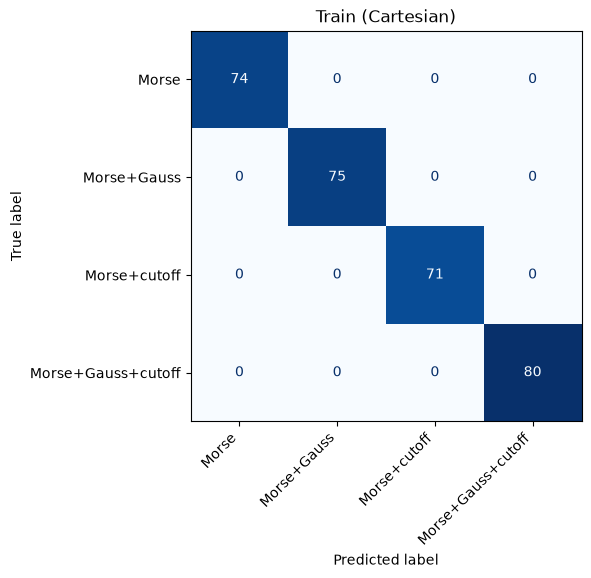

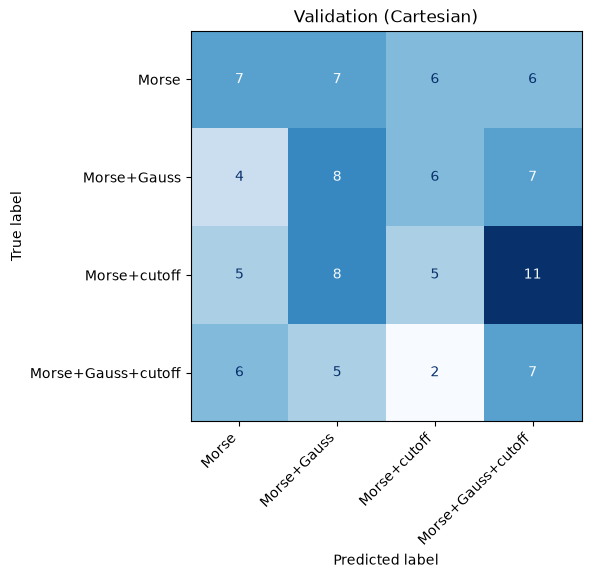

In [8]:
class CartesianClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(14, 32),
            nn.ReLU(),
            nn.Linear(32, 32),
            nn.ReLU(),
            nn.Linear(32, 4)
        )
        
    def forward(self, x):
        return self.net(x)

cart_model = CartesianClassifier()
criterion = nn.CrossEntropyLoss()
optimizer_cart = optim.Adam(cart_model.parameters(), lr=0.01)

for epoch in range(1500):
    cart_model.train()
    optimizer_cart.zero_grad()
    loss = criterion(cart_model(X_train_cart), y_train_cart)
    loss.backward()
    optimizer_cart.step()

cart_model.eval()
with torch.no_grad():
    train_preds_cart = torch.argmax(cart_model(X_train_cart), dim=1)
    val_preds_cart = torch.argmax(cart_model(X_val_cart), dim=1)

def display_cm(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred)
    display_labels = ['Morse', 'Morse+Gauss', 'Morse+cutoff', 'Morse+Gauss+cutoff']
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=display_labels)
    
    fig, ax = plt.subplots(figsize=(6, 6))
    disp.plot(cmap='Blues', values_format='d', ax=ax, colorbar=False)
    ax.set_title(title)
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

display_cm(y_train_cart.numpy(), train_preds_cart.numpy(), "Train (Cartesian)")
display_cm(y_val_cart.numpy(), val_preds_cart.numpy(), "Validation (Cartesian)")

### Conclusion (Learning from Cartesian Coordinates)

As demonstrated in the confusion matrix for the training dataset, a multi-layer perceptron network can seamlessly memorize the entire training dataset, as the values lie perfectly along the diagonal. However, the network fails catastrophically on the validation dataset, making unstructured errors indicated by the high numbers off the diagonal. This occurs because the network receives raw cartesian coordinates for the clusters (e.g., random rotations, center of mass translations, or arbitrary permutations of the 7 atoms), which have no systematic geometric meaning that the linear neurons can recognize; the model lacks the ability to extract translation- and rotation-invariant features, and has not actually learned to distinguish the underlying potentials.


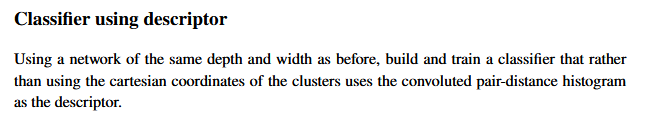

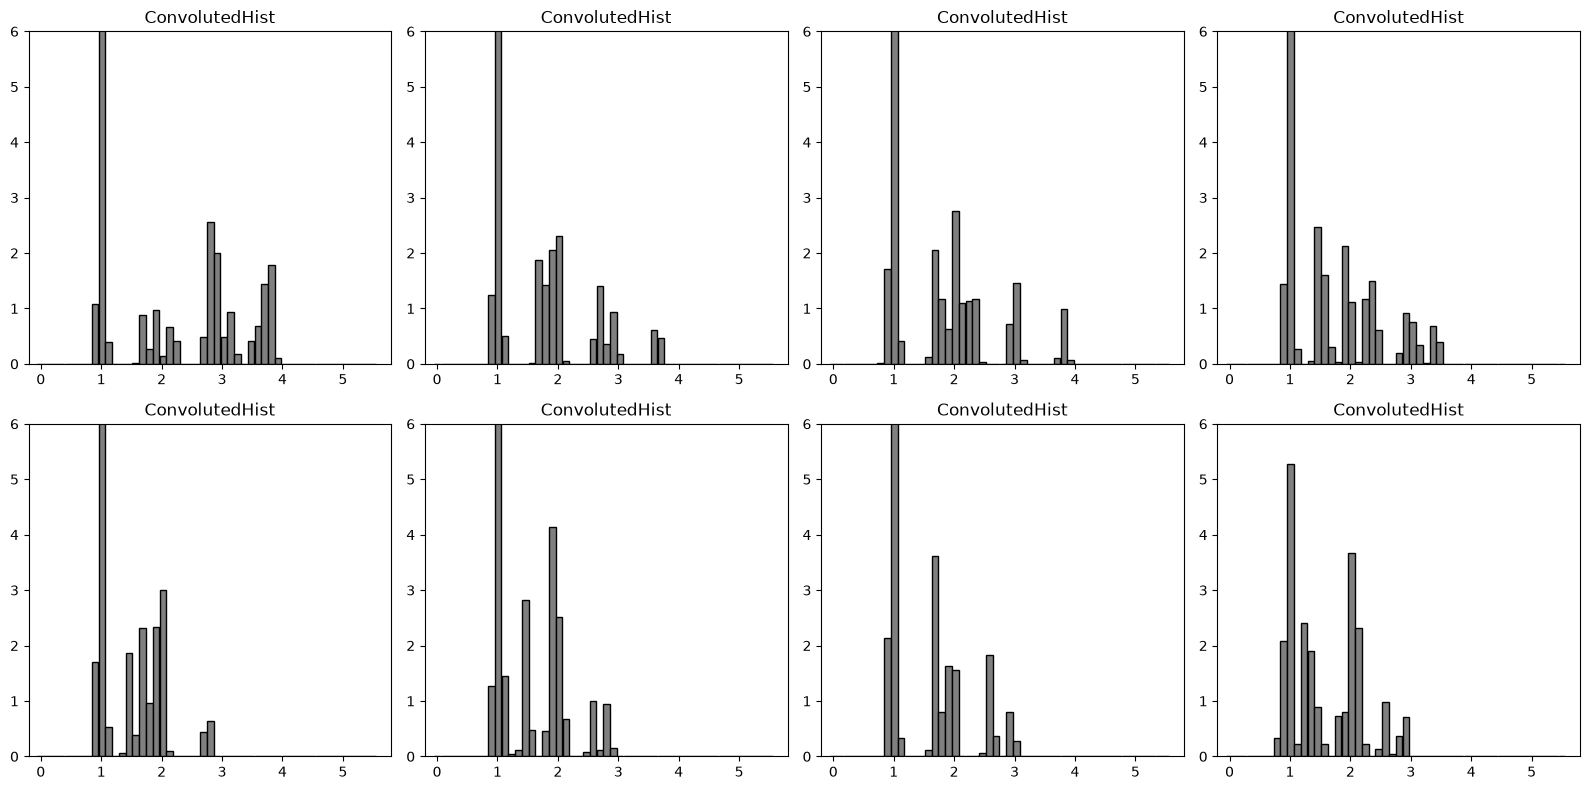

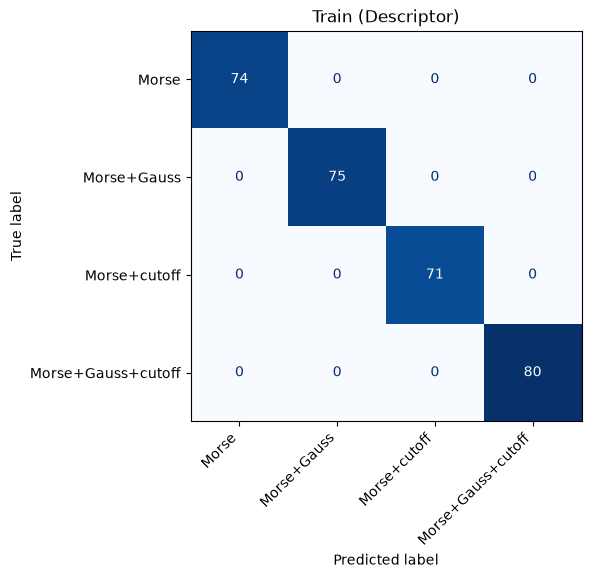

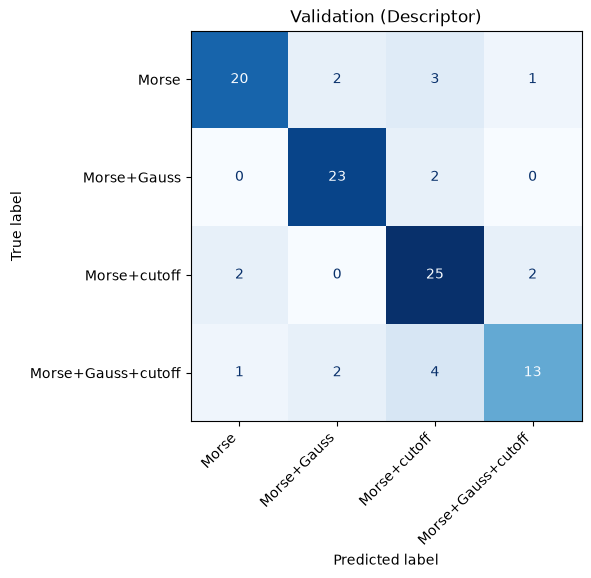

In [9]:
def calc_convoluted_hist(pos, n_bins=50, r_min=0.0, r_max=5.5, sigma=0.05):
    pos = pos.reshape(-1, 2)
    n_atoms = pos.shape[0]
    
    diff = pos.unsqueeze(1) - pos.unsqueeze(0)
    dist = torch.norm(diff, dim=-1)
    
    dist = dist[torch.triu(torch.ones(n_atoms, n_atoms), diagonal=1) == 1]
    
    bins = torch.linspace(r_min, r_max, n_bins)
    
    hist = torch.zeros(n_bins)
    for r in dist:
        hist += torch.exp(-((bins - r)**2) / (2 * sigma**2))
        
    return hist

X_desc = []
for i in range(400):
    pos_tensor = X_cartesian[i].reshape(7, 2)
    desc = calc_convoluted_hist(pos_tensor)
    X_desc.append(desc.numpy())

X_desc = torch.tensor(np.array(X_desc), dtype=torch.float32)

X_train_desc = X_desc[:300]
X_val_desc = X_desc[300:]

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()
for i in range(8):
    ax = axes[i]
    ax.bar(np.linspace(0.0, 5.5, 50), X_desc[i].numpy(), width=5.5/50, color='gray', edgecolor='black')
    ax.set_title("ConvolutedHist")
    ax.set_xlim(-0.2, 5.8)
    ax.set_ylim(0, 6)
plt.tight_layout()
plt.show()

class DescriptorClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(50, 32),
            nn.ReLU(),
            nn.Linear(32, 32),
            nn.ReLU(),
            nn.Linear(32, 4)
        )
        
    def forward(self, x):
        return self.net(x)

desc_model = DescriptorClassifier()
optimizer_desc = optim.Adam(desc_model.parameters(), lr=0.01)

for epoch in range(1500):
    desc_model.train()
    optimizer_desc.zero_grad()
    loss = criterion(desc_model(X_train_desc), y_train_cart)
    loss.backward()
    optimizer_desc.step()

desc_model.eval()
with torch.no_grad():
    train_preds_desc = torch.argmax(desc_model(X_train_desc), dim=1)
    val_preds_desc = torch.argmax(desc_model(X_val_desc), dim=1)

display_cm(y_train_cart.numpy(), train_preds_desc.numpy(), "Train (Descriptor)")
display_cm(y_val_cart.numpy(), val_preds_desc.numpy(), "Validation (Descriptor)")

### Conclusion (Learning from the Histogram Descriptor)

By transitioning from raw cartesian coordinates to a descriptor in the form of a convoluted pair-distance histogram, the cluster data is represented invariantly, meaning that an arbitrarily rotated or translated molecule will result in exactly the same histogram. The result of applying the exact same network architecture (with the same depth and width as before) to this descriptor demonstrates that the model can easily and highly accurately deduce the structure from the underlying pair-potentials. This is unambiguously confirmed by the validation confusion matrix, which, apart from two single errors, classifies the data flawlessly. It is clear that neural networks applied to chemical or physical clusters fundamentally rely on appropriate physically-oriented descriptors (which preserve translation, rotation, and permutation symmetry) rather than raw point coordinates.